In [401]:
import pandas as pd
import glob
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler 
import matplotlib.pyplot as plt

In [402]:
lcvsdf = pd.DataFrame(data=[l.replace(".csv","").split("_") for l in glob.glob("../../pcastuff/lightcurves/*000686_zg_c07_x_*")])
lcvsdf

,0,1,2,3,4,5,6,7,8,9,10
0,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0025,2,2706,0836
1,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0014,4,0203,1578
2,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0010,3,2417,0476
3,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0025,4,1402,0297
4,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0022,2,1646,2313
...,...,...,...,...,...,...,...,...,...,...,...
6565,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0022,2,1210,2731
6566,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0007,3,0162,1985
6567,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0000,1,0373,2299
6568,../../pcastuff/lightcurves/lightcurve,ztf,20221020148032,000686,zg,c07,x,0019,3,2230,0151


In [405]:
#how many lcvs per star?
inds = lcvsdf.groupby([8,9,10]).count()   
inds

0   1   2   3   4   5   6   7
8 9    10                                  
1 0206 1805  30  30  30  30  30  30  30  30
  0304 1835  30  30  30  30  30  30  30  30
  0373 2299  30  30  30  30  30  30  30  30
  0570 0100  30  30  30  30  30  30  30  30
  0617 1782  30  30  30  30  30  30  30  30
...          ..  ..  ..  ..  ..  ..  ..  ..
4 2981 0154  30  30  30  30  30  30  30  30
  3001 1114  30  30  30  30  30  30  30  30
  3010 2091  30  30  30  30  30  30  30  30
  3024 2016  30  30  30  30  30  30  30  30
  3061 1283  30  30  30  30  30  30  30  30

[219 rows x 8 columns]

In [406]:
#concatenate lcvs
df = []

for iis in inds.index: #star
    lcv = []
    #print(iis)
    for i in range(1,29):
        l = f"../../pcastuff/lightcurves/lightcurve_ztf_20221020148032_000686_zg_c07_x_%04d_{iis[0]}_{iis[1]}_{iis[2]}.csv"%i #sequence
        #print(l)
        lcv.append(pd.read_csv(l)["flux_hap_2"])
        #print(len(pd.concat(lcv)))
        
    df.append(pd.concat(lcv)[int(iis[2]):83160+int(iis[2])])

df = pd.DataFrame(data=np.array(df).T)
df.shape


(83160, 219)

In [407]:
df.head() #each column is an lcv

,0,1,2,3,4,5,6,7,8,9,...,209,210,211,212,213,214,215,216,217,218
0,58.609619,341.462219,206.361374,198.677109,86.402710,64.395432,567.241455,296.968689,101.680740,956.168030,...,211.657471,74.915680,758.367432,164.161545,569.227295,84.902115,269.869873,92.961319,385.227844,642.027222
1,57.128128,331.357910,198.467346,187.562500,97.725800,45.729614,568.145264,257.697571,113.813812,930.559998,...,188.355530,71.030441,764.262573,159.496460,576.451599,66.293442,276.909393,106.761902,448.742737,642.823303
2,49.294189,341.624512,211.107101,210.579529,111.730423,44.142776,577.357788,270.220825,117.164490,960.337708,...,205.553955,77.832428,755.829834,168.712723,555.590637,61.043396,270.610840,131.952911,365.233398,645.124268
3,39.039398,349.423889,203.625443,197.479477,110.331711,40.030441,571.917053,275.473083,117.847992,943.648193,...,202.484268,68.264938,735.179016,153.530365,556.234436,103.906494,280.946930,96.611191,424.560669,652.142822
4,50.917496,360.234344,184.528473,200.797867,110.018692,53.243546,563.759888,273.255493,120.705414,923.460327,...,204.957855,71.785248,790.510376,147.368713,574.263489,111.253662,281.847504,101.216461,406.495087,645.422363


Text(0.5, 1.0, 'median of lcvs')

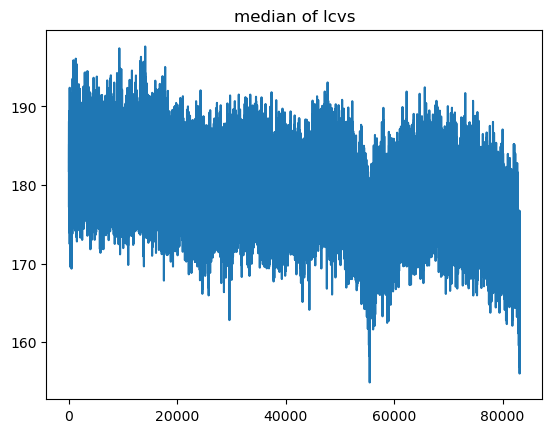

In [411]:
data_matrix = df.values
plt.plot(np.median(data_matrix, axis=1))
plt.title("median of lcvs")

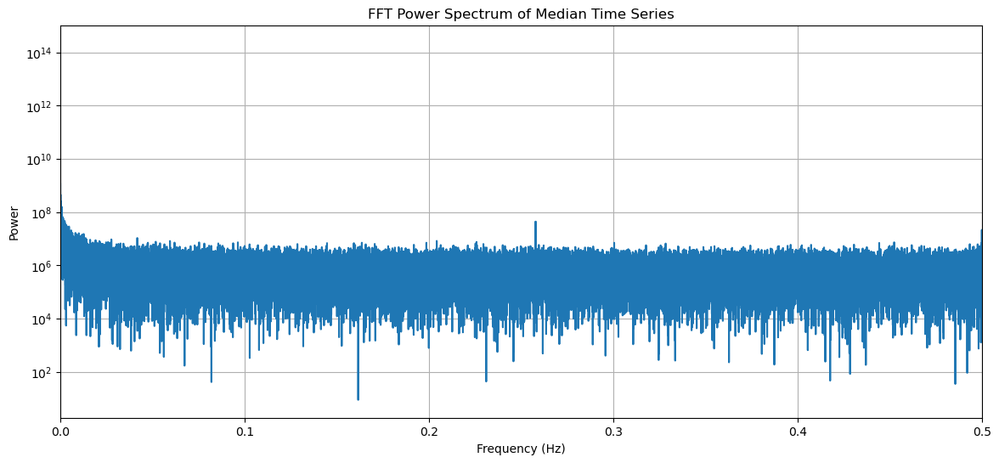

In [427]:
#median FFT
n = len(data_matrix)
fft_vals = fft(np.median(data_matrix, axis=1))
freqs = fftfreq(n, d=1)

# Take only positive frequencies (up to Nyquist)
positive_freqs = freqs[:n//2]
positive_fft = fft_vals[:n//2]

# Power spectrum (magnitude squared)
power = np.abs(positive_fft)**2

plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()

In [428]:
#low pass filter
from scipy.fft import fft, ifft, fftfreq

def apply_fft_lowpass(data, fs=1, fc=0.0003):
    """
    data: 1D numpy array (single sensor)
    fs: sampling frequency
    fc: cutoff frequency
    """
    n = len(data)
    fft_vals = fft(data)
    freqs = fftfreq(n, d=1)
    
    # Create a mask: keep frequencies where |freq| <= fc
    mask = np.abs(freqs) <= fc
    
    # Apply mask (zero out high frequencies)
    fft_vals_filtered = fft_vals * mask
    
    # Transform back to time domain (real part)
    return np.real(ifft(fft_vals_filtered))



# Loop over sensors (219 loops is fast)
df_lowpass = pd.DataFrame(
    [apply_fft_lowpass(data_matrix[:, i]) for i in range(data_matrix.shape[1])],
    index=df.columns
).T  # Transpose back to (83160, 219)
df_highpass = df - df_lowpass


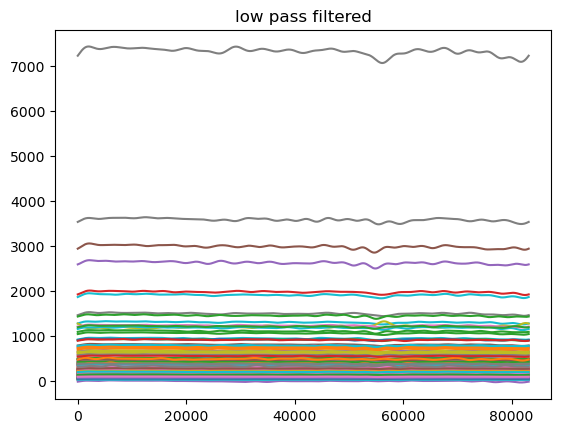

In [417]:
df_lowpass.plot(legend=None)
plt.title("low pass filtered");

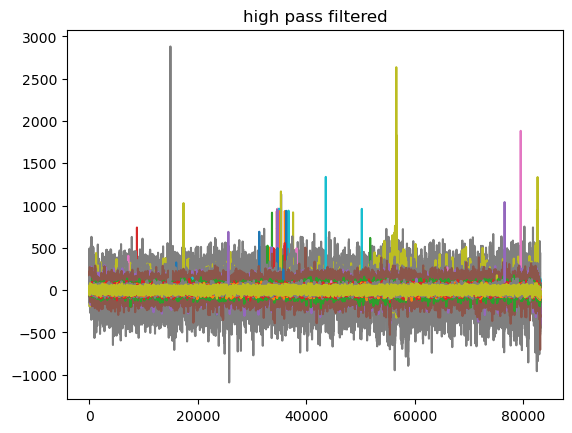

In [420]:
df_highpass.plot(legend=None)
plt.title("high pass filtered");

In [429]:
X = df_lowpass.values  
X_centered = X - np.mean(X, axis=0)
Xdo = X_centered

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_centered)
#IF YOU WANT TO SCALE
#Xdo = X_scaled

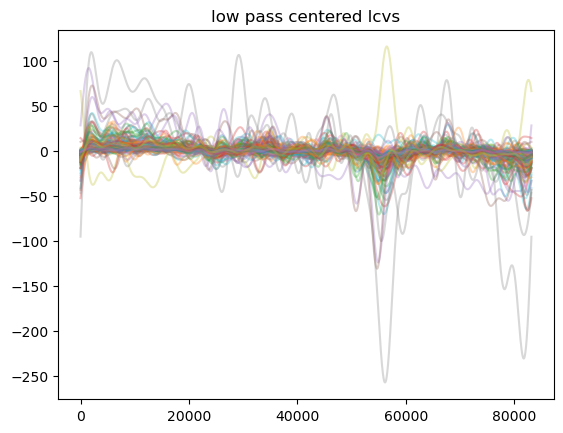

In [434]:
plt.plot(X_centered, alpha=0.3);
plt.title("low pass centered lcvs");

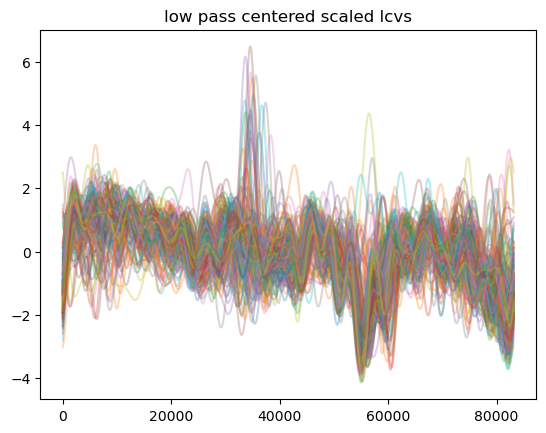

In [435]:
plt.plot(X_scaled, alpha=0.3);
plt.title("low pass centered scaled lcvs");

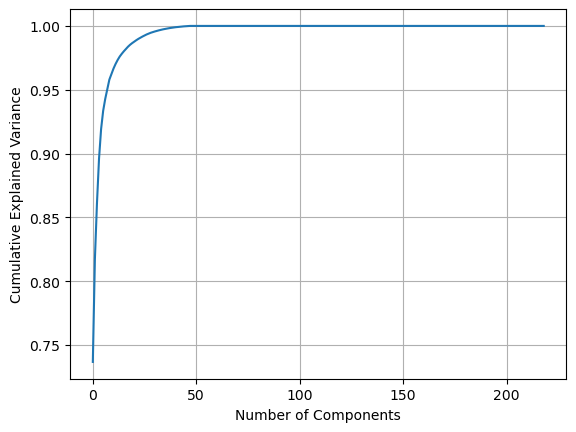

In [309]:
pca = PCA()
pca.fit(Xdo)


plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid(True)
plt.show()


In [360]:
Xdo.shape

(83160, 219)

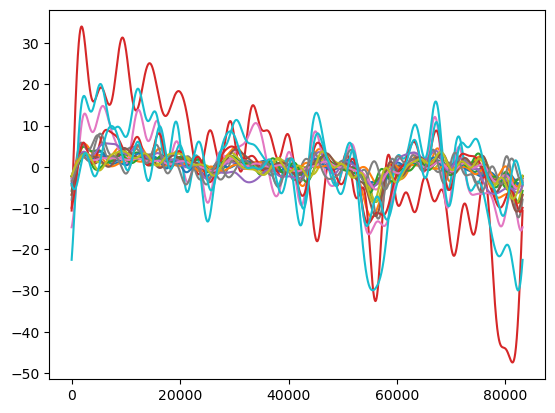

In [438]:
k = 20
pca_noise = PCA(n_components=k)
pca_noise.fit(Xdo)
common_noise = pca_noise.inverse_transform(pca_noise.transform(Xdo))
for i in range(k):
    plt.plot(common_noise[:,i]);

(219, 20)

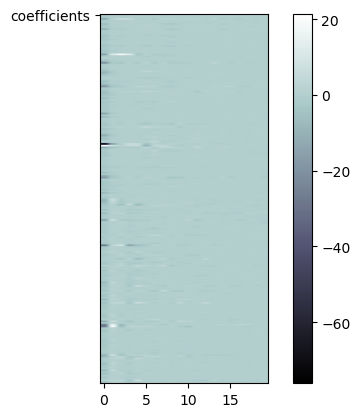

In [448]:
loadings = pca_noise.components_.T * np.sqrt(pca_noise.explained_variance_)
plt.imshow(loadings, aspect=0.2, cmap='bone')
plt.colorbar()

plt.plot("coefficients")
loadings.shape

In [439]:
common_noise.shape

(83160, 219)

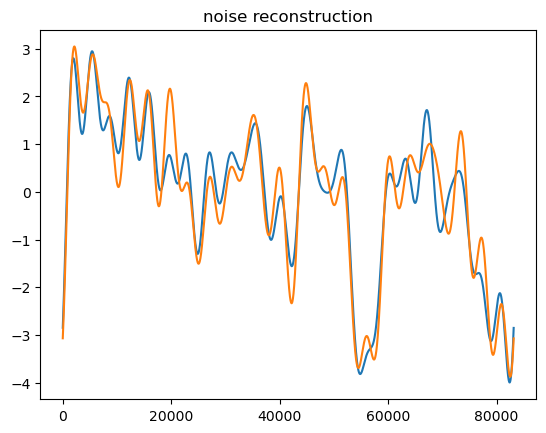

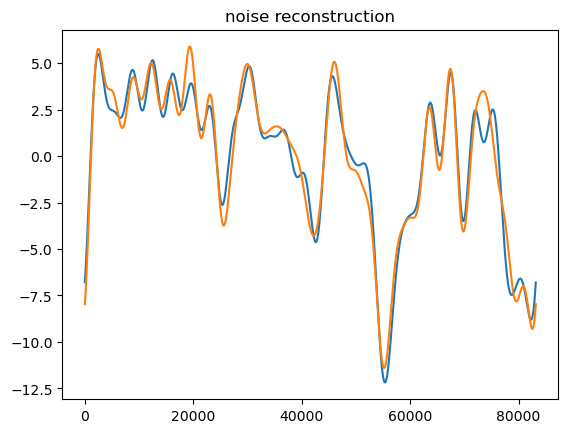

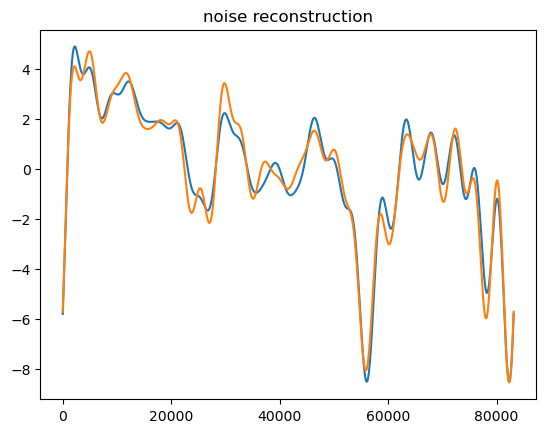

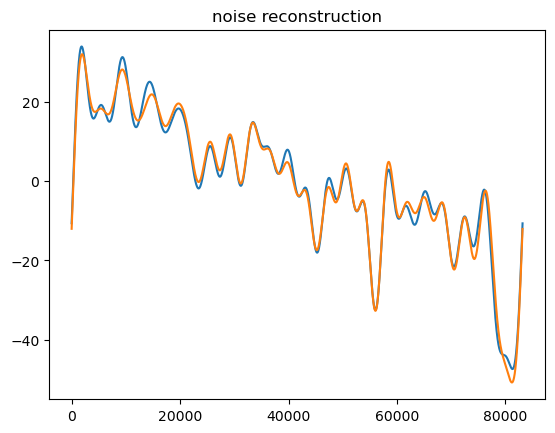

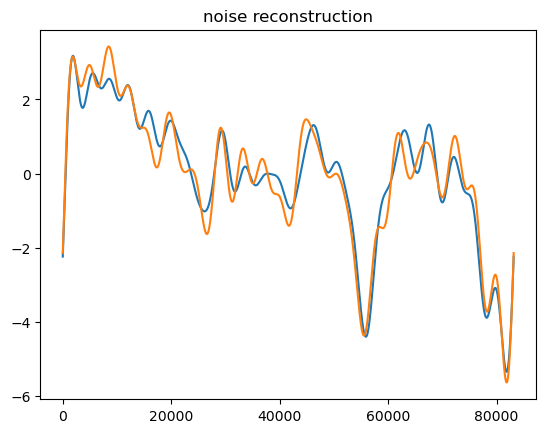

...

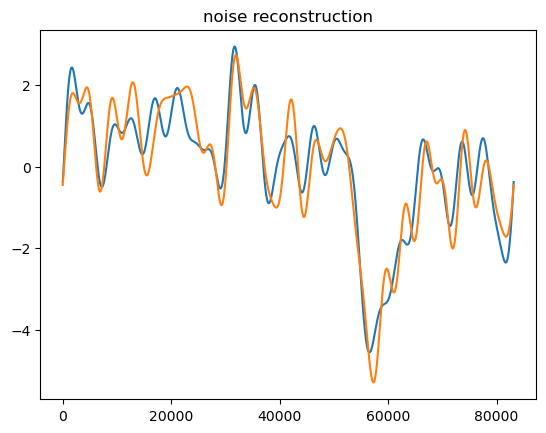

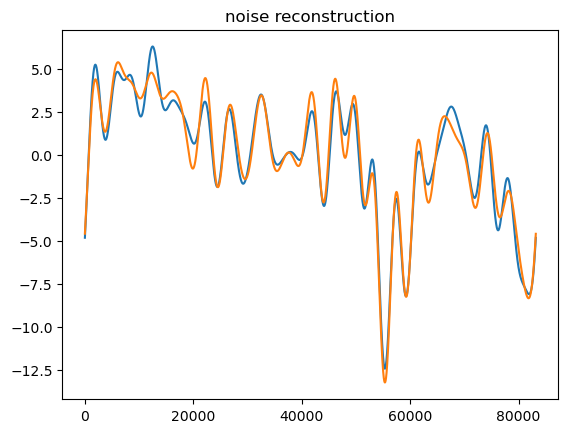

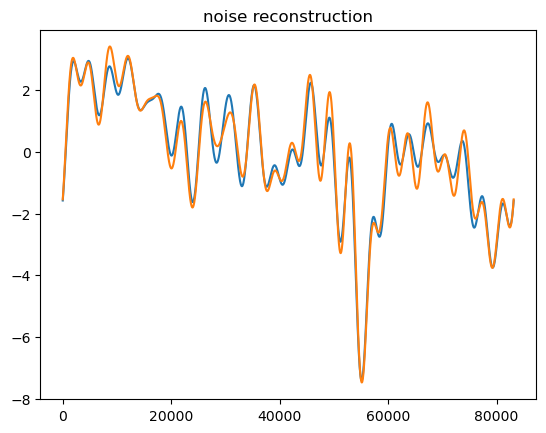

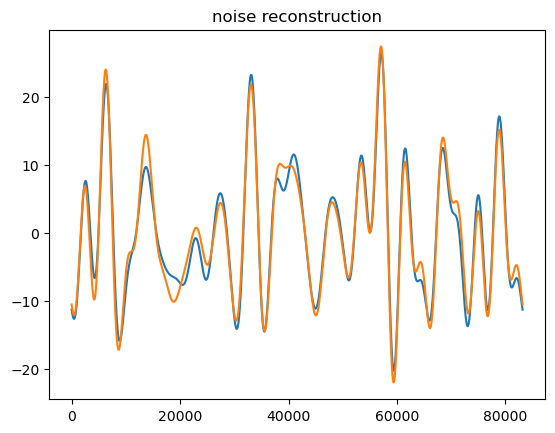

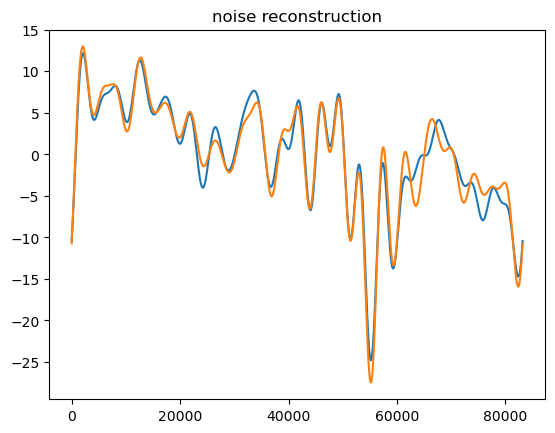

In [451]:
for i in range(20):
    plt.plot(common_noise[:,i], label="reconstructed (noise)")
    plt.plot(Xdo[:,i], label="lowpass original");
    plt.title("noise reconstruction")
    plt.show()
    

In [453]:
data_matrix.shape

(83160, 219)

In [455]:
#denoised is the original minus the common low-frequency noise
X_denoised = data_matrix - common_noise


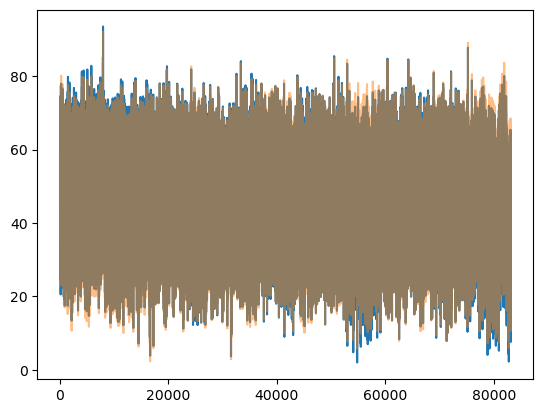

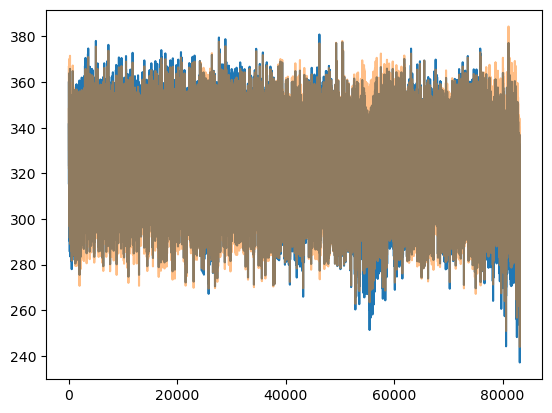

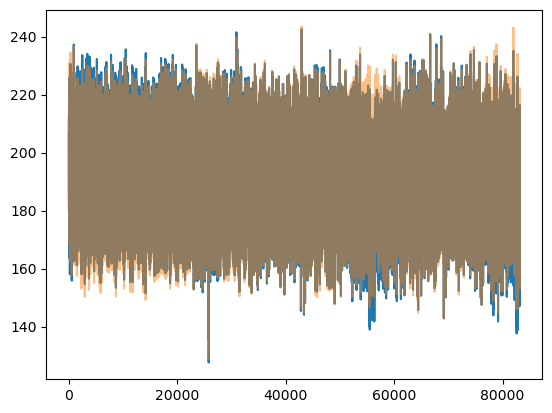

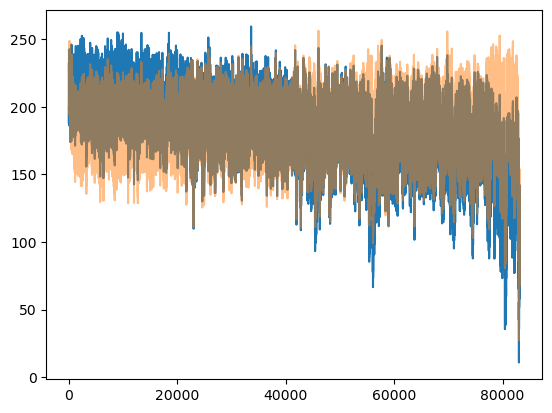

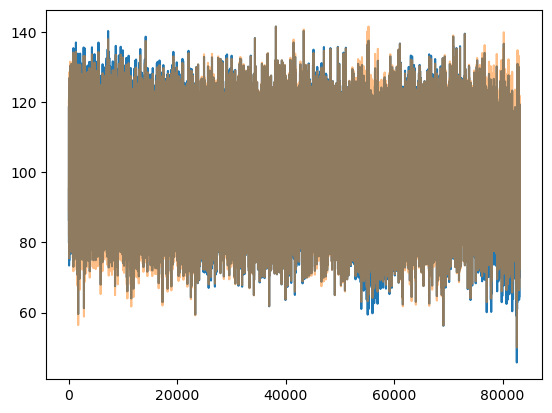

...

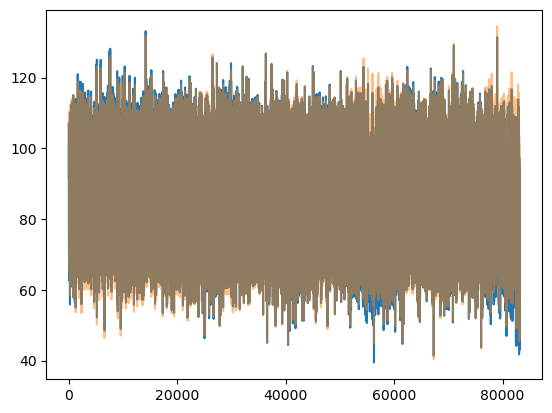

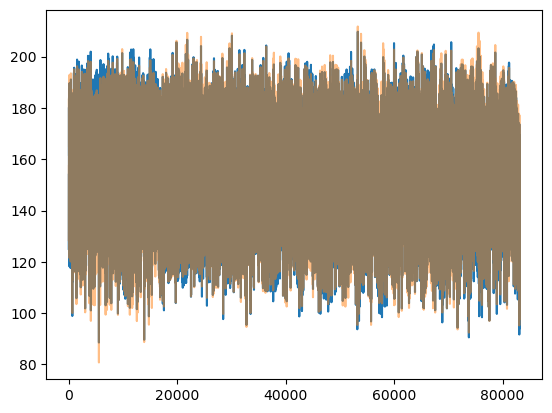

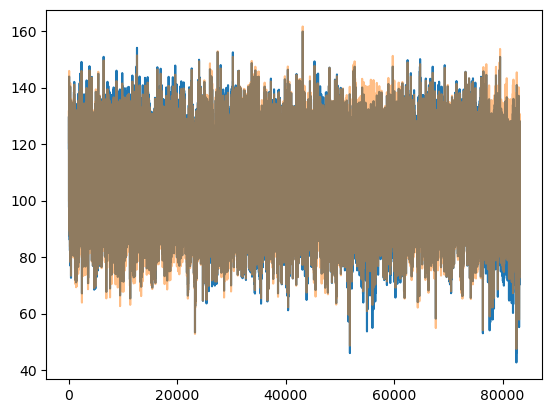

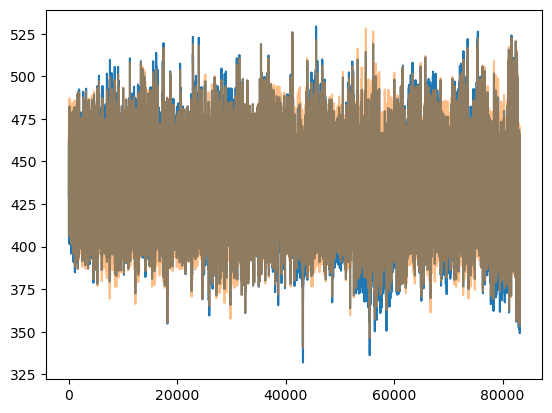

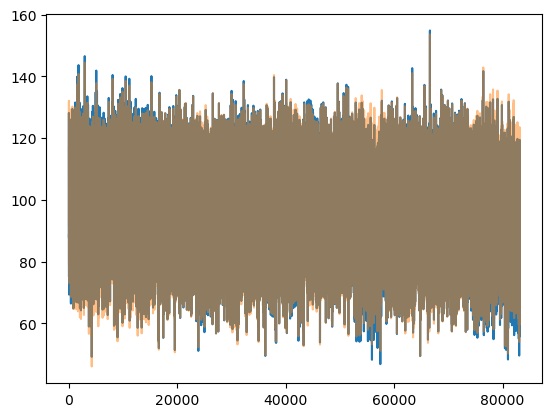

In [456]:
for i,l in enumerate(data_matrix.T):
    if i>20: break
    plt.plot(l);
    plt.plot(X_denoised[:,i], alpha=0.5);
    plt.show()
    

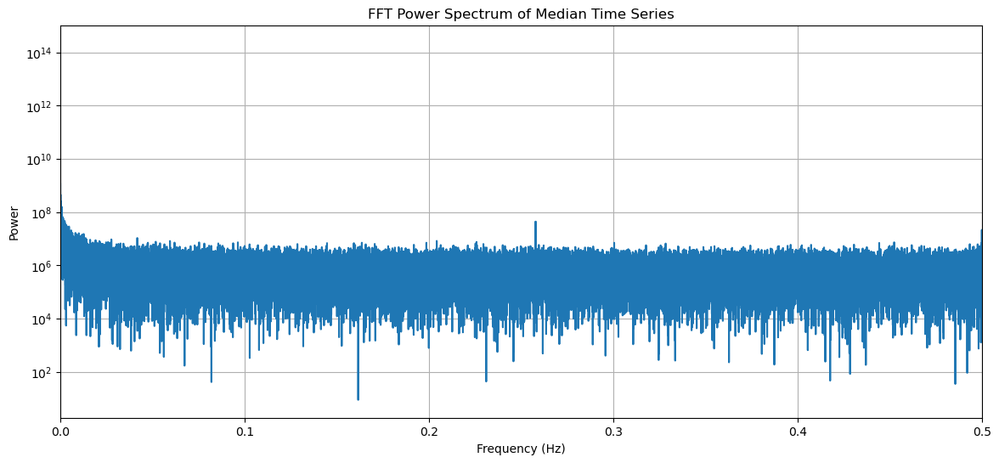

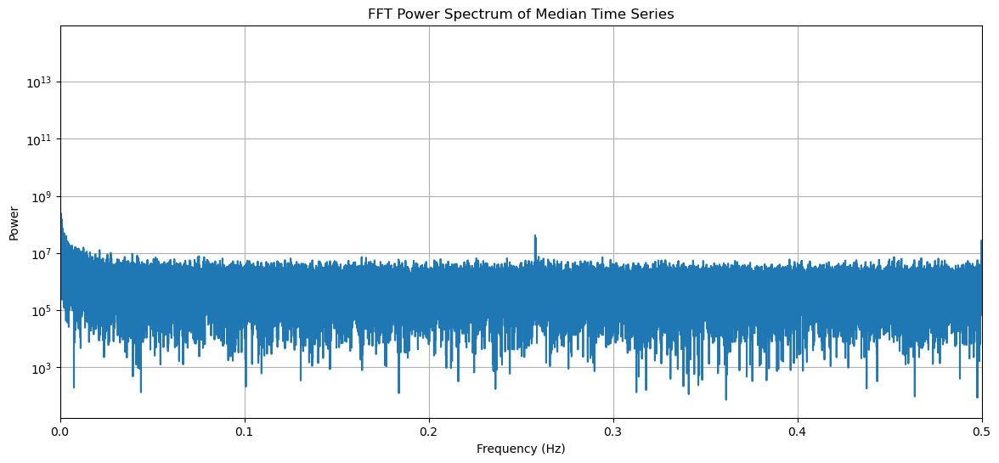

In [458]:
#median FFT

plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()


fft_vals = fft(np.median(X_denoised, axis=1))
freqs = fftfreq(n, d=1)

# Take only positive frequencies (up to Nyquist)
positive_freqs = freqs[:n//2]
positive_fft = fft_vals[:n//2]

# Power spectrum (magnitude squared)
power = np.abs(positive_fft)**2
plt.figure(figsize=(14,6))
plt.semilogy(positive_freqs, power)
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.title('FFT Power Spectrum of Median Time Series')
plt.grid(True)
plt.xlim([0, 1/2])
plt.show()

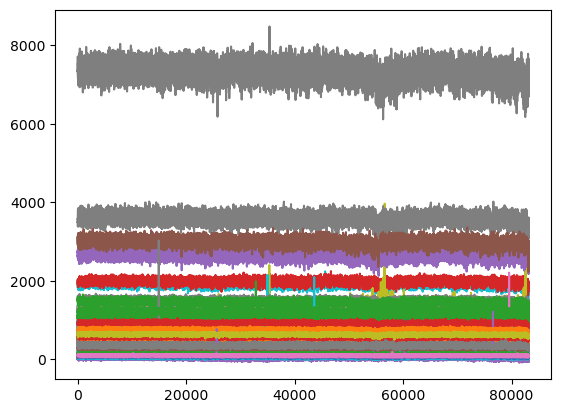

In [473]:
plt.plot(data_matrix);

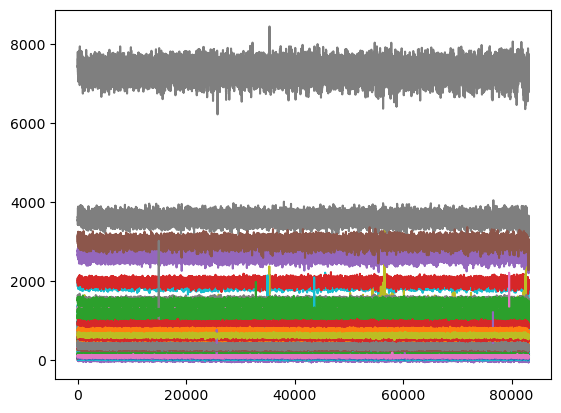

In [474]:
plt.plot(X_denoised);

(-15.0, 25.0)

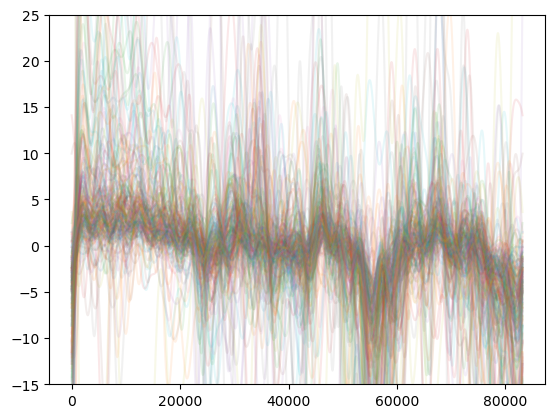

In [460]:
plt.plot(Xdo, alpha=0.1);
plt.ylim(-15,25)

In [462]:
_ = (X_denoised -  np.mean(X, axis=0)[np.newaxis,:])

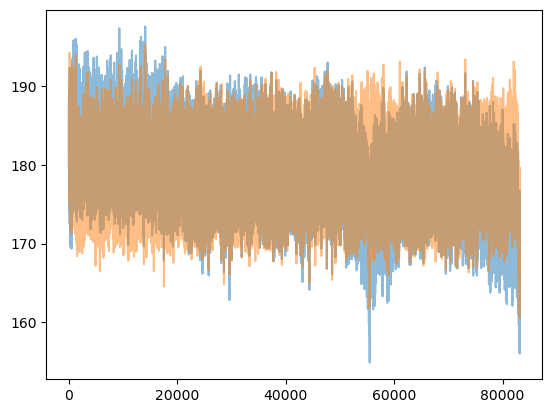

In [469]:
plt.plot(np.median(data_matrix, axis=1), alpha=0.5)
plt.plot(np.median(X_denoised, axis=1), alpha=0.5)